# Mini Project 3: Fashion Item Recognition

## Project Overview

The objective of this project is to develop a deep learning model
that can recognize different fashion items using image classification.

We use the Fashion-MNIST dataset and PyTorch to build a
Convolutional Neural Network (CNN).

### Objectives
- Load and visualize fashion images.
- Prepare the dataset.
- Build and train a CNN model.
- Evaluate classification performance.
- Display a prediction gallery.
- Compare ANN and CNN models.
- Save the trained model.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

print("PyTorch Version:", torch.__version__)
print("NumPy Version:", np.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch Version: 2.14.1+cpu
NumPy Version: 2.4.6
Device: CPU


## 2. Loading the Fashion-MNIST Dataset

Fashion-MNIST is a dataset containing 70,000 grayscale images
of clothing items.

It contains 60,000 training images and 10,000 testing images.
Each image has a size of 28 × 28 pixels and belongs to one
of 10 fashion categories.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 305kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.65MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.3MB/s]

Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])


## 3. Visualizing Fashion-MNIST Images

Display sample images from the dataset along with their corresponding clothing labels.

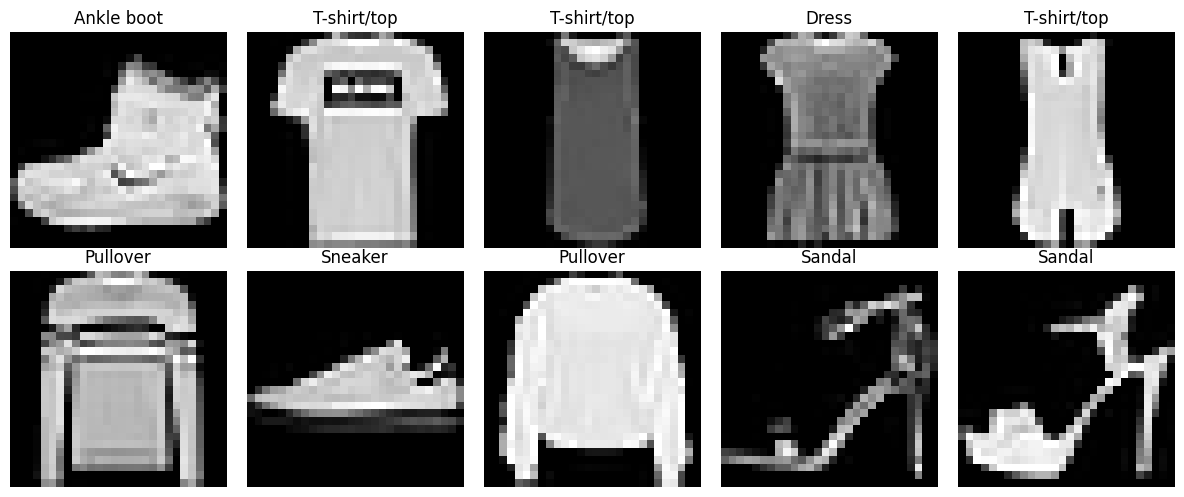

In [3]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # Reverse normalization for display
    image = image.squeeze() * 0.3530 + 0.2860

    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Dataset Splitting and DataLoaders

Split the 60,000 training images into 50,000 training images
and 10,000 validation images.

Use DataLoader to load images in batches of 64.

In [4]:
train_size = 50000
val_size = 10000

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 64

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Testing samples:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training samples: 50000
Validation samples: 10000
Testing samples: 10000
Training batches: 782
Validation batches: 157
Testing batches: 157


## 5. Building the CNN Model

Build a Convolutional Neural Network using PyTorch.

The model contains:
- Two convolutional layers.
- ReLU activation functions.
- Max pooling layers.
- Fully connected layers.
- Dropout for reducing overfitting.

The output layer predicts one of the 10 fashion categories.

In [5]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


cnn_model = FashionCNN()

print(cnn_model)

FashionCNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 6. Model Training Configuration

Configure the loss function, optimizer and number of training epochs.

- Loss Function: CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Epochs: 5

In [6]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

epochs = 5

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", epochs)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epochs: 5


## 7. Training the CNN Model

Train the CNN using the training dataset.

Evaluate its performance on the validation dataset after every epoch.

Record training loss, validation loss, training accuracy and validation accuracy.

In [7]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(epochs):

    # Training phase
    cnn_model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss / train_total
    train_accuracy = 100 * train_correct / train_total

    # Validation phase
    cnn_model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # Store results
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Accuracy: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/5] | Train Loss: 0.4844 | Train Accuracy: 82.27% | Val Loss: 0.3324 | Val Accuracy: 88.15%
Epoch [2/5] | Train Loss: 0.3069 | Train Accuracy: 88.83% | Val Loss: 0.2808 | Val Accuracy: 89.72%
Epoch [3/5] | Train Loss: 0.2594 | Train Accuracy: 90.44% | Val Loss: 0.2492 | Val Accuracy: 90.90%
Epoch [4/5] | Train Loss: 0.2291 | Train Accuracy: 91.57% | Val Loss: 0.2335 | Val Accuracy: 91.33%
Epoch [5/5] | Train Loss: 0.2049 | Train Accuracy: 92.38% | Val Loss: 0.2420 | Val Accuracy: 91.56%


## 8. Training and Validation Curves

Visualize the training loss, validation loss, training accuracy
and validation accuracy over five epochs.

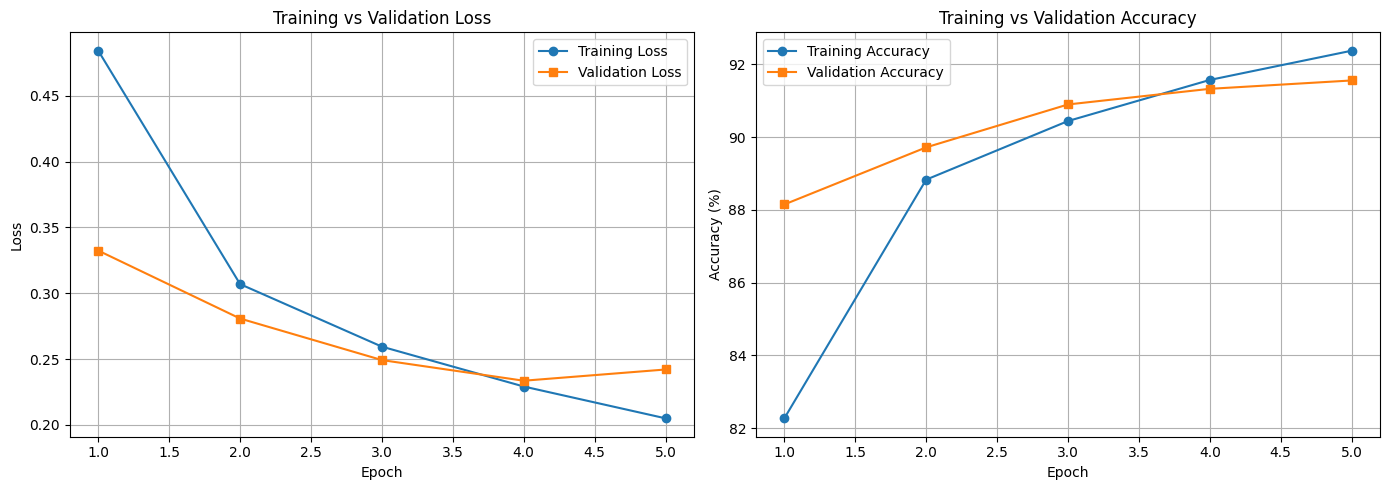

In [8]:
epoch_range = range(1, epochs + 1)

plt.figure(figsize=(14, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(epoch_range, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epoch_range, history["val_loss"], marker="s", label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(epoch_range, history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(epoch_range, history["val_accuracy"], marker="s", label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## 9. Model Evaluation

Evaluate the trained CNN model using the test dataset.

Calculate the overall test accuracy to measure how well
the model recognizes unseen fashion images.

In [9]:
cnn_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print("Correct Predictions:", correct)
print("Total Test Images:", total)
print(f"Test Accuracy: {test_accuracy:.2f}%")

Correct Predictions: 9086
Total Test Images: 10000
Test Accuracy: 90.86%


## 10. Fashion Item Prediction Gallery

Display 10 unseen test images with their actual labels,
predicted labels and prediction confidence.

Use green titles for correct predictions and red titles
for incorrect predictions.

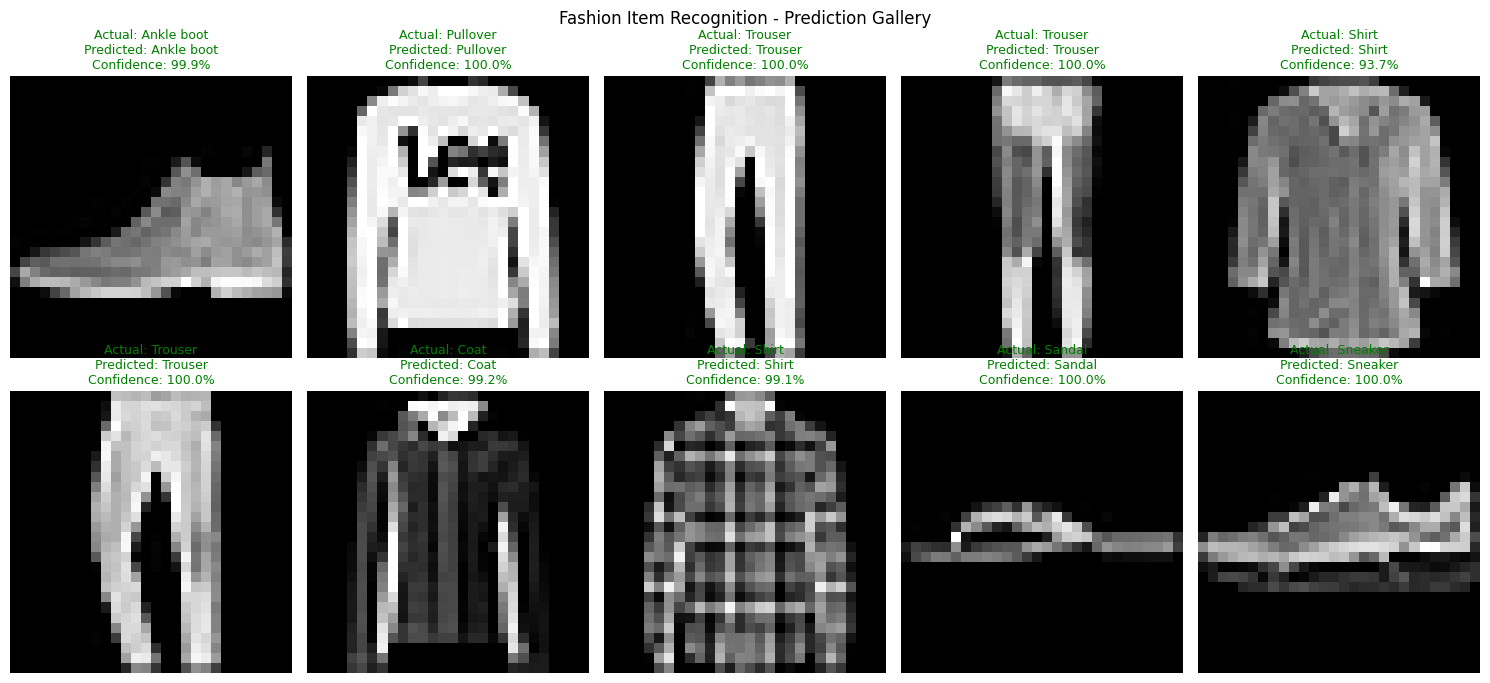

In [10]:
cnn_model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = cnn_model(images)
    probabilities = torch.softmax(outputs, dim=1)

    predictions = outputs.argmax(dim=1)
    confidence = probabilities.max(dim=1).values

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):

    image = images[i].squeeze() * 0.3530 + 0.2860

    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]

    color = "green" if labels[i] == predictions[i] else "red"

    ax.imshow(image, cmap="gray")

    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence[i].item()*100:.1f}%",
        color=color,
        fontsize=9
    )

    ax.axis("off")

plt.suptitle("Fashion Item Recognition - Prediction Gallery")
plt.tight_layout()
plt.show()

## 11. ANN vs CNN Comparison

Build a simple fully connected neural network (ANN)
and compare its performance with the CNN model.

Both models will use the same training and testing datasets.

In [11]:
class FashionANN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


ann_model = FashionANN()

print(ann_model)

FashionANN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 12. Training the ANN Model

Train the fully connected ANN using the Fashion-MNIST training dataset.

Evaluate its performance on the validation dataset for five epochs.

In [12]:
ann_optimizer = optim.Adam(
    ann_model.parameters(),
    lr=0.001
)

ann_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(epochs):

    ann_model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        ann_optimizer.zero_grad()

        outputs = ann_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        ann_optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = 100 * train_correct / train_total

    ann_model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = ann_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = 100 * val_correct / val_total

    ann_history["train_loss"].append(train_loss)
    ann_history["train_accuracy"].append(train_accuracy)
    ann_history["val_loss"].append(val_loss)
    ann_history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Accuracy: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/5] | Train Loss: 0.4801 | Train Accuracy: 82.88% | Val Loss: 0.4130 | Val Accuracy: 85.20%
Epoch [2/5] | Train Loss: 0.3626 | Train Accuracy: 86.85% | Val Loss: 0.3660 | Val Accuracy: 86.64%
Epoch [3/5] | Train Loss: 0.3243 | Train Accuracy: 88.13% | Val Loss: 0.3543 | Val Accuracy: 86.84%
Epoch [4/5] | Train Loss: 0.3005 | Train Accuracy: 88.95% | Val Loss: 0.3286 | Val Accuracy: 87.97%
Epoch [5/5] | Train Loss: 0.2816 | Train Accuracy: 89.55% | Val Loss: 0.3135 | Val Accuracy: 88.54%


## 13. ANN and CNN Test Evaluation

Evaluate both trained models on the 10,000 Fashion-MNIST test images.

Compare their final test accuracy.

In [13]:
def evaluate_model(model, model_name):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    print(f"{model_name} Test Accuracy: {accuracy:.2f}%")

    return accuracy


ann_test_accuracy = evaluate_model(ann_model, "ANN")
cnn_test_accuracy = evaluate_model(cnn_model, "CNN")

ANN Test Accuracy: 87.86%
CNN Test Accuracy: 90.86%


## 14. ANN vs CNN – Final Comparison

| Metric | ANN | CNN |
|---|---:|---:|
| Training Accuracy | 89.55% | 92.38% |
| Validation Accuracy | 88.54% | 91.56% |
| Test Accuracy | 87.86% | 90.86% |
| Training Loss | 0.2816 | 0.2049 |
| Validation Loss | 0.3135 | 0.2420 |

### Conclusion

Both ANN and CNN models were trained and evaluated using the Fashion-MNIST dataset.

The ANN achieved 87.86% test accuracy, while the CNN achieved 90.86%.

CNN performed better because convolutional layers extract spatial features such as edges, shapes and patterns from images.

Therefore, CNN is more suitable for this image classification task than the simple fully connected ANN used in this experiment.

## 15. Saving Trained Models

Save the trained CNN and ANN model weights for future use.

In [14]:
torch.save(cnn_model.state_dict(), "fashion_cnn.pth")
torch.save(ann_model.state_dict(), "fashion_ann.pth")

print("CNN model saved successfully!")
print("ANN model saved successfully!")

CNN model saved successfully!
ANN model saved successfully!


## 16. Error Analysis – Five Misclassified Images

Identify five test images where the CNN predicted the wrong clothing category.

Display the actual category and predicted category for each image.

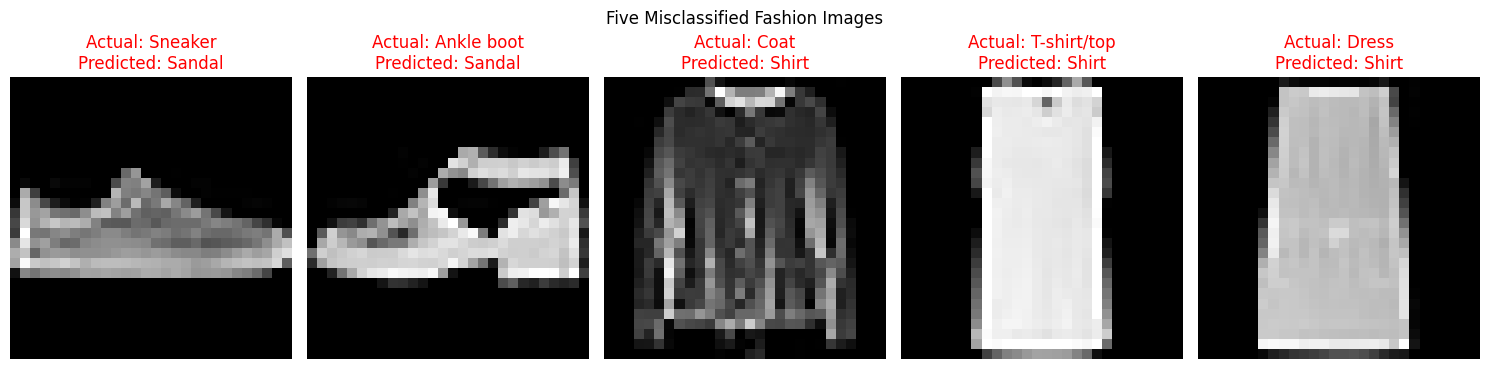

In [15]:
cnn_model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []

with torch.no_grad():
    for images, labels in test_loader:

        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(images[idx])
            wrong_labels.append(labels[idx].item())
            wrong_predictions.append(predictions[idx].item())

            if len(wrong_images) == 5:
                break

        if len(wrong_images) == 5:
            break

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):

    image = wrong_images[i].squeeze() * 0.3530 + 0.2860

    actual = class_names[wrong_labels[i]]
    predicted = class_names[wrong_predictions[i]]

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="red"
    )
    ax.axis("off")

plt.suptitle("Five Misclassified Fashion Images")
plt.tight_layout()
plt.show()

## 17. Error Analysis and Observations

The CNN model was used to identify five incorrectly classified test images.

| Actual Category | Predicted Category |
|---|---|
| Sneaker | Sandal |
| Ankle boot | Sandal |
| Coat | Shirt |
| T-shirt/top | Shirt |
| Dress | Shirt |

### Observations

1. Sneaker and sandal have some similar visual features.
2. Ankle boots and sandals can be confused because of their shapes.
3. Coats and shirts have similar clothing structures.
4. T-shirts and shirts are visually similar.
5. Dresses may be confused with shirts because of low image resolution.

### Conclusion

The CNN achieved 90.86% test accuracy on Fashion-MNIST.

Although the model performs well, it sometimes confuses visually similar clothing categories. Higher image resolution, data augmentation and a more advanced CNN architecture could potentially improve classification performance.